In [92]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn, optim
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

plt.style.use("dark_background")
np.random.seed(42)
torch.manual_seed(42)

---
# 1. Data Splitting Strategy

**CRITICAL CONCEPT:** How we split data affects hyperparameter tuning!

**Strategy:**
1. Split 80/20: Training+Validation vs Test
2. Use 5-fold CV on Training+Validation for tuning learning rate
3. **Keep Test set completely untouched** until final evaluation


In [93]:
dataset = load_breast_cancer()
X = dataset.data
y = dataset.target

print(X.shape)
print(np.unique(y, return_counts=True))

(569, 30)
(array([0, 1]), array([212, 357]))


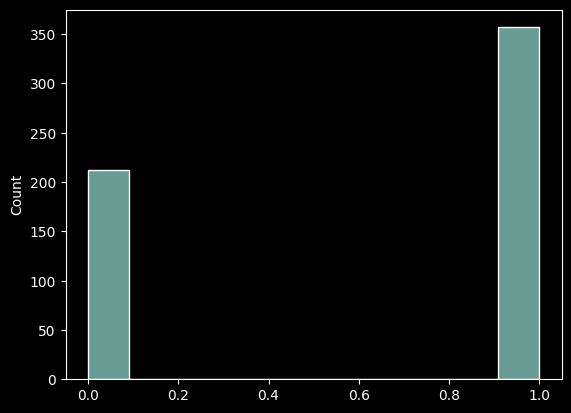

In [94]:
sns.histplot(y)
plt.show()

In [95]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(np.unique(y_train, return_counts=True))
print(np.unique(y_test, return_counts=True))

(array([0, 1]), array([170, 285]))
(array([0, 1]), array([42, 72]))


---
# 2. PyTorch Neural Network

Simple architecture:
- **Input:** 30 features
- **Hidden:** 64 neurons + ReLU
- **Output:** 2 neurons (softmax applied in CrossEntropyLoss)


In [96]:
class SimpleNN(nn.Module):
    def __init__(self, input_size: int = 30, hidden_size: int = 15, num_classes: int = 2) -> None:
        super().__init__()
        self.neural_netowrk = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output = self.neural_netowrk(x)
        return output

# device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu"
# print(f"Device Used: {device}")

model = SimpleNN()
print(model)

for param in model.parameters():
    print(type(param), param.size())

print(f"\nParameters: {sum(p.numel() for p in model.parameters()):,}")

SimpleNN(
  (neural_netowrk): Sequential(
    (0): Linear(in_features=30, out_features=15, bias=True)
    (1): ReLU()
    (2): Linear(in_features=15, out_features=2, bias=True)
  )
)
<class 'torch.nn.parameter.Parameter'> torch.Size([15, 30])
<class 'torch.nn.parameter.Parameter'> torch.Size([15])
<class 'torch.nn.parameter.Parameter'> torch.Size([2, 15])
<class 'torch.nn.parameter.Parameter'> torch.Size([2])

Parameters: 497


---
# 3. Training Function

Returns **learning & validation curves** for every epoch.


In [97]:
def train_model(model: nn.Module, X_train, y_train, X_val, y_val, epochs: int, learning_rate: float = 0.01):
    """
    Train model and return learning & validation curves

    Returns:
        train_losses, val_losses, train_accs, val_accs
    """
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    for epoch in range(epochs):
        model.train()

        optimizer.zero_grad()

        outputs = model(X_train)
        loss = criterion(outputs, y_train)

        loss.backward()
        optimizer.step()

        _, train_pred = torch.max(outputs, 1)
        train_acc = (train_pred == y_train).float().mean().item()

        train_losses.append(loss.item())
        train_accs.append(train_acc)

        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val)
            val_loss = criterion(val_outputs, y_val)
            _, val_pred = torch.max(val_outputs, 1)
            val_acc = (val_pred == y_val).float().mean().item()

            val_losses.append(val_loss.item())
            val_accs.append(val_acc)

    return train_losses, val_losses, train_accs, val_accs

print("Training function defined")

Training function defined


---
# 4. Learning Rate Tuning with 5-Fold CV with a validation curve

We'll test 5 different learning rates and use cross-validation to find the best one.


In [98]:
learning_rates = [0.0001, 0.0005, 0.001, 0.005, 0.01]

print(f"Testing {len(learning_rates)} learning rates with 5-fold CV...")
print(f"Total models: {len(learning_rates)} × 5 = 25")

Testing 5 learning rates with 5-fold CV...
Total models: 5 × 5 = 25


In [99]:
import random
import numpy as np
import torch
from sklearn.model_selection import KFold, ShuffleSplit
from sklearn.preprocessing import StandardScaler

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

FIXED_SEED = 42
set_all_seeds(FIXED_SEED)

lr_results = {}

# Cross-validation for all learning rates
for lr in learning_rates:
    print(f"\nTesting LR = {lr}...")

    kfold = KFold(n_splits=5, shuffle=True, random_state=42)
    fold_val_accs = []
    fold_train_accs = []
    fold_val_curves = []

    for fold, (train_idx, test_idx) in enumerate(kfold.split(X_train), 1):
        X_train_fold = X_train[train_idx]
        y_train_fold = y_train[train_idx]
        X_val_fold = X_train[test_idx]
        y_val_fold = y_train[test_idx]

        scaler = StandardScaler()
        X_train_fold = scaler.fit_transform(X_train_fold)
        X_val_fold = scaler.transform(X_val_fold)

        X_train_tensor = torch.FloatTensor(X_train_fold)
        y_train_tensor = torch.LongTensor(y_train_fold)
        X_val_tensor = torch.FloatTensor(X_val_fold)
        y_val_tensor = torch.LongTensor(y_val_fold)

        model_fold = SimpleNN()
        train_losses, val_losses, train_accs, val_accs = train_model(
            model_fold, X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor, learning_rate=lr, epochs=100
        ) 

        fold_val_accs.append(val_accs[-1])
        fold_train_accs.append(train_accs[-1])
        fold_val_curves.append(val_accs)

    mean_acc = np.mean(fold_val_accs)
    std_acc = np.std(fold_val_accs)
    mean_train_acc = np.mean(fold_train_accs)

    lr_results[lr] = {
        "mean_acc": mean_acc,
        "std_acc": std_acc,
        "mean_train_acc": mean_train_acc,
        "fold_accs": fold_val_accs,
        "fold_train_accs": fold_train_accs,
        "val_curves": fold_val_curves,
    }

    print(f"  Mean: {mean_acc:.4f} ± {std_acc:.4f}")

print("\n Cross-validation complete!")


Testing LR = 0.0001...
  Mean: 0.7253 ± 0.1297

Testing LR = 0.0005...
  Mean: 0.9341 ± 0.0184

Testing LR = 0.001...
  Mean: 0.9626 ± 0.0256

Testing LR = 0.005...
  Mean: 0.9736 ± 0.0179

Testing LR = 0.01...
  Mean: 0.9802 ± 0.0108

 Cross-validation complete!



Extracting mean scores for Validation Curve...
Best Learning Rate found: 0.01


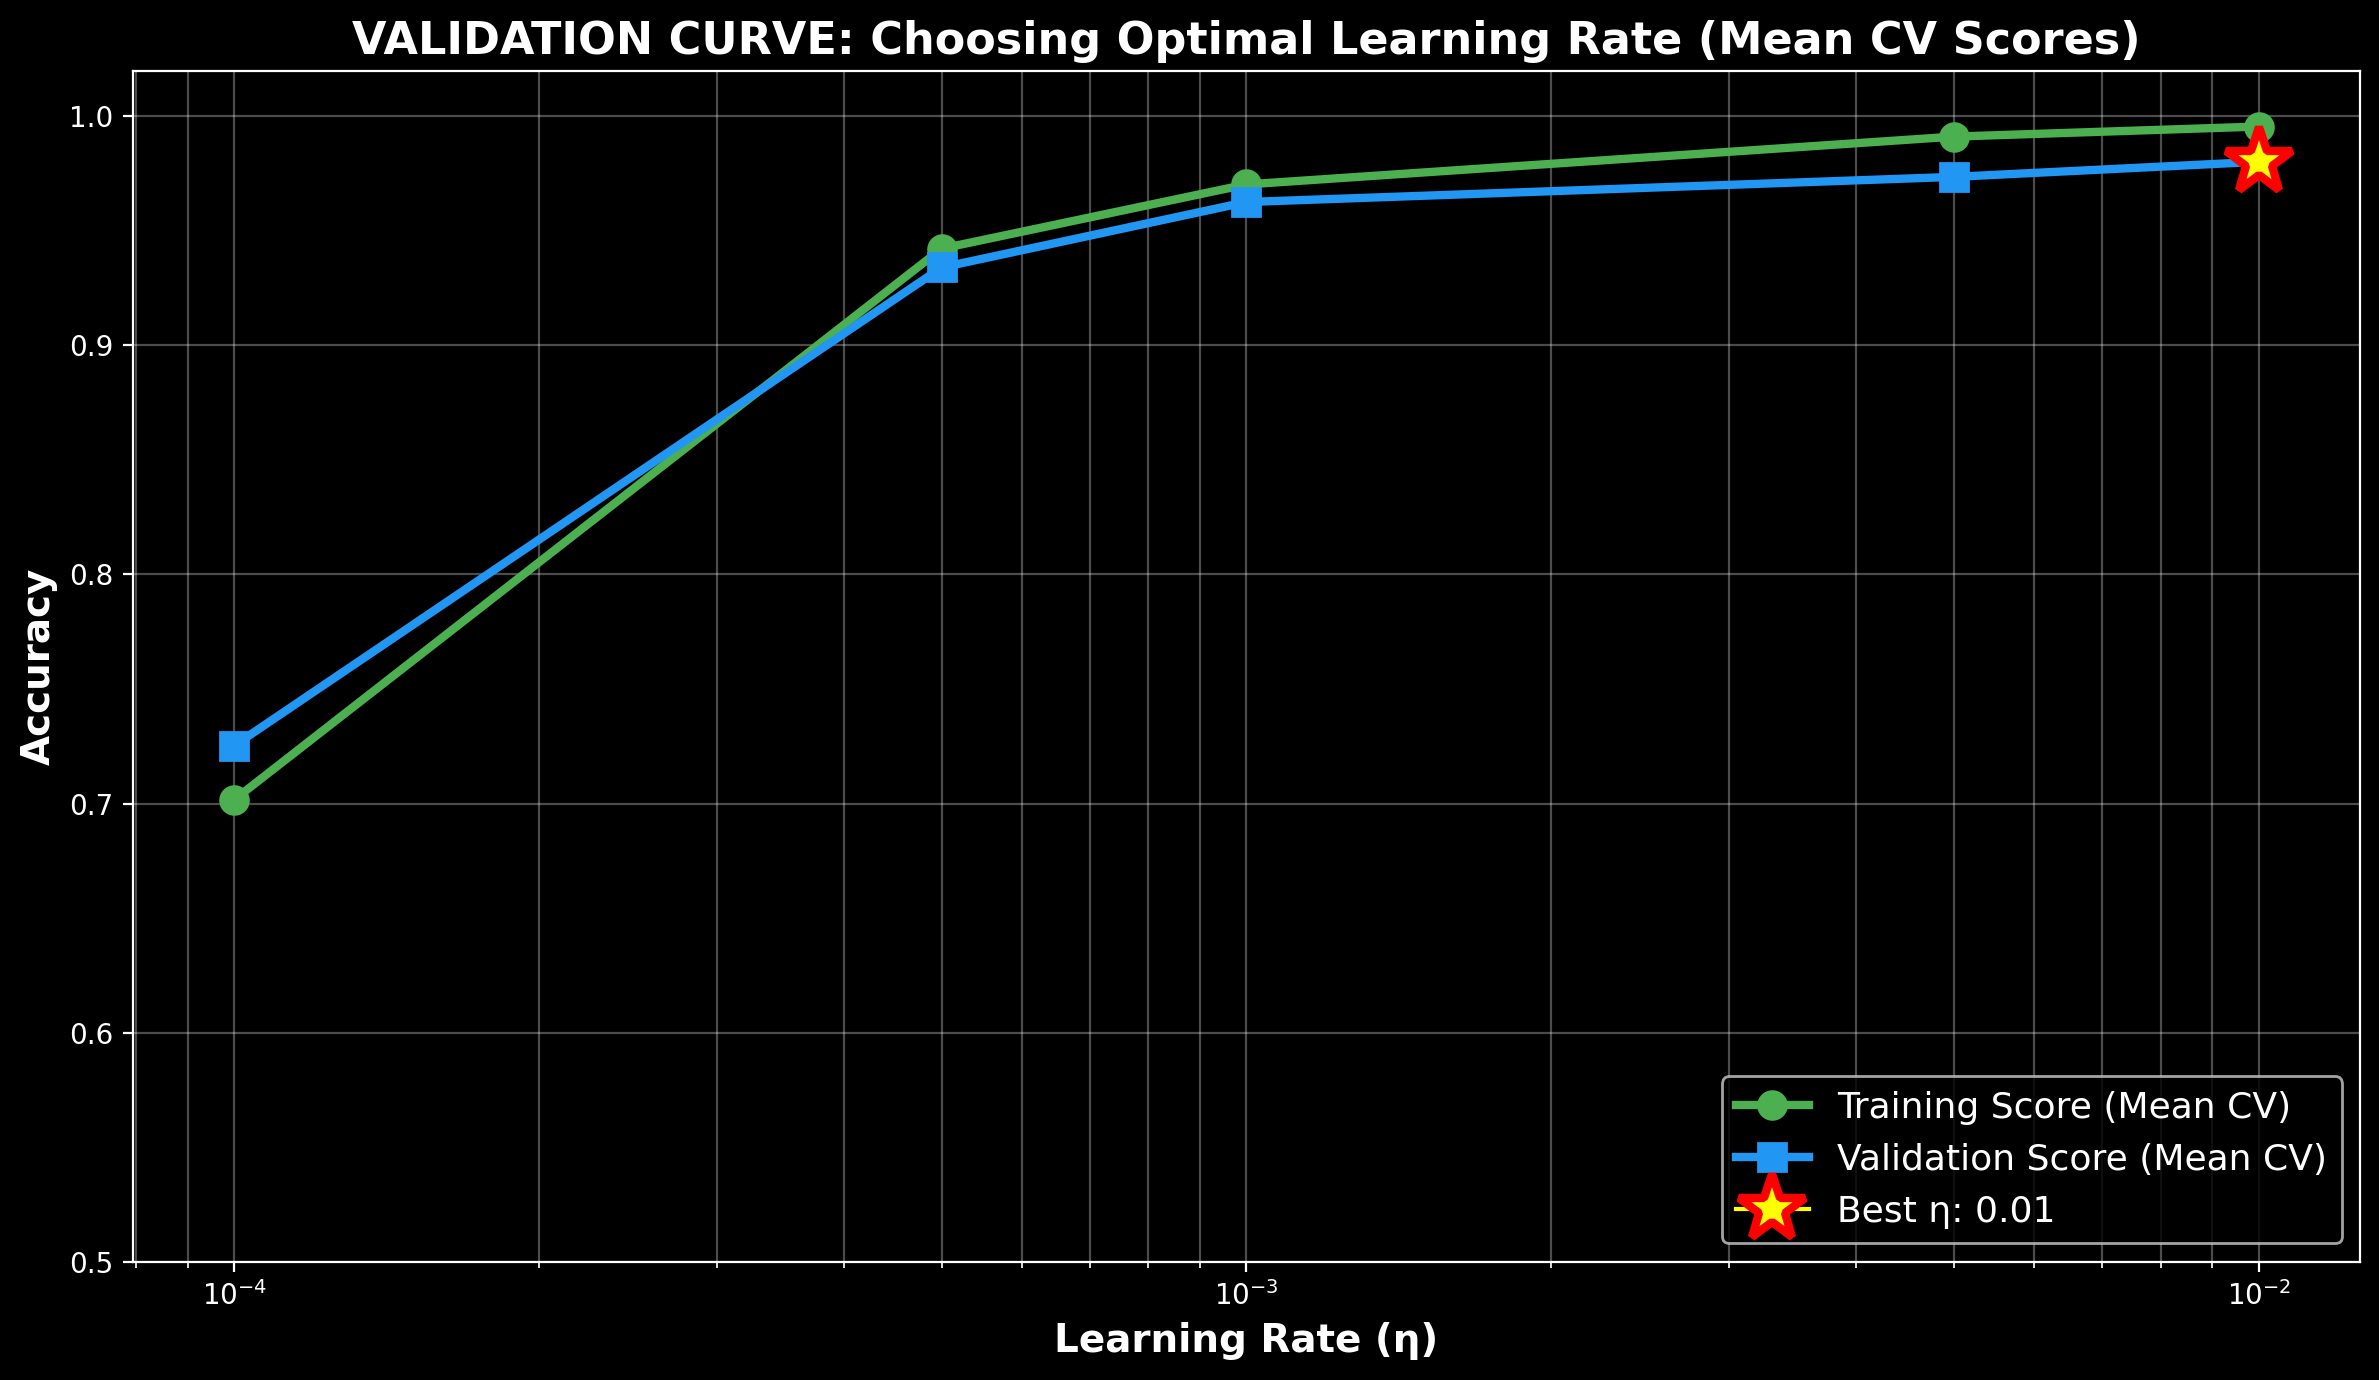

In [100]:
import numpy as np
import matplotlib.pyplot as plt

print("\nExtracting mean scores for Validation Curve...")

train_scores_cv = [lr_results[lr]["mean_train_acc"] for lr in learning_rates]
val_scores_cv = [lr_results[lr]["mean_acc"] for lr in learning_rates]

best_lr = max(lr_results, key=lambda lr: lr_results[lr]["mean_acc"])
print(f"Best Learning Rate found: {best_lr}")

# Plot Validation Curve
fig, ax = plt.subplots(figsize=(12, 7), dpi=200)

ax.plot(learning_rates, train_scores_cv, marker='o', markersize=10,
        label='Training Score (Mean CV)', color='#4CAF50', linewidth=3)
ax.plot(learning_rates, val_scores_cv, marker='s', markersize=10,
        label='Validation Score (Mean CV)', color='#2196F3', linewidth=3)

best_idx = learning_rates.index(best_lr)
ax.plot(best_lr, val_scores_cv[best_idx], marker='*', markersize=25,
        color='yellow', markeredgecolor='red', markeredgewidth=3,
        label=f'Best η: {best_lr}', zorder=10)

ax.set_xlabel('Learning Rate (η)', fontsize=14, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=14, fontweight='bold')
ax.set_title('VALIDATION CURVE: Choosing Optimal Learning Rate (Mean CV Scores)',
            fontsize=16, fontweight='bold')
ax.set_xscale('log')
ax.legend(fontsize=13, loc='lower right')
ax.grid(alpha=0.3, which='both')
ax.set_ylim([0.5, 1.02])

plt.tight_layout()
plt.show()

---
# 5. Learning Curve


In [101]:
# LEARNING CURVE: X=training samples, Y=accuracy
print("Generating Learning Curve...")

train_sizes = [50, 100, 150, 200, 250, 300, 364]
train_scores_lc = []
val_scores_lc = []

kfold_lc = KFold(n_splits=5, shuffle=True, random_state=42)
train_idx, val_idx = next(kfold_lc.split(X_train))

X_train_full = X_train[train_idx]
y_train_full = y_train[train_idx]
X_val_lc = X_train[val_idx]
y_val_lc = y_train[val_idx]

for size in train_sizes:
    X_train_subset = X_train_full[:size]
    y_train_subset = y_train_full[:size]

    scaler_lc = StandardScaler()
    X_train_scaled = scaler_lc.fit_transform(X_train_subset) # notice when we standardize using fit_transform the mean and std are claculated and applied (data is z-scored)
    # but with validation we transform directly because we already calculated the mean and std using training
    X_val_scaled = scaler_lc.transform(X_val_lc)

    X_train_tensor = torch.FloatTensor(X_train_scaled)
    y_train_tensor = torch.LongTensor(y_train_subset)
    X_val_tensor = torch.FloatTensor(X_val_scaled)
    y_val_tensor = torch.LongTensor(y_val_lc)

    model_lc = SimpleNN()
    _, _, train_accs, val_accs = train_model(
        model_lc, X_train_tensor, y_train_tensor,
        X_val_tensor, y_val_tensor, learning_rate=best_lr, epochs=100
    )

    train_scores_lc.append(train_accs[-1])
    val_scores_lc.append(val_accs[-1])

print("Learning curve generated")

Generating Learning Curve...
Learning curve generated


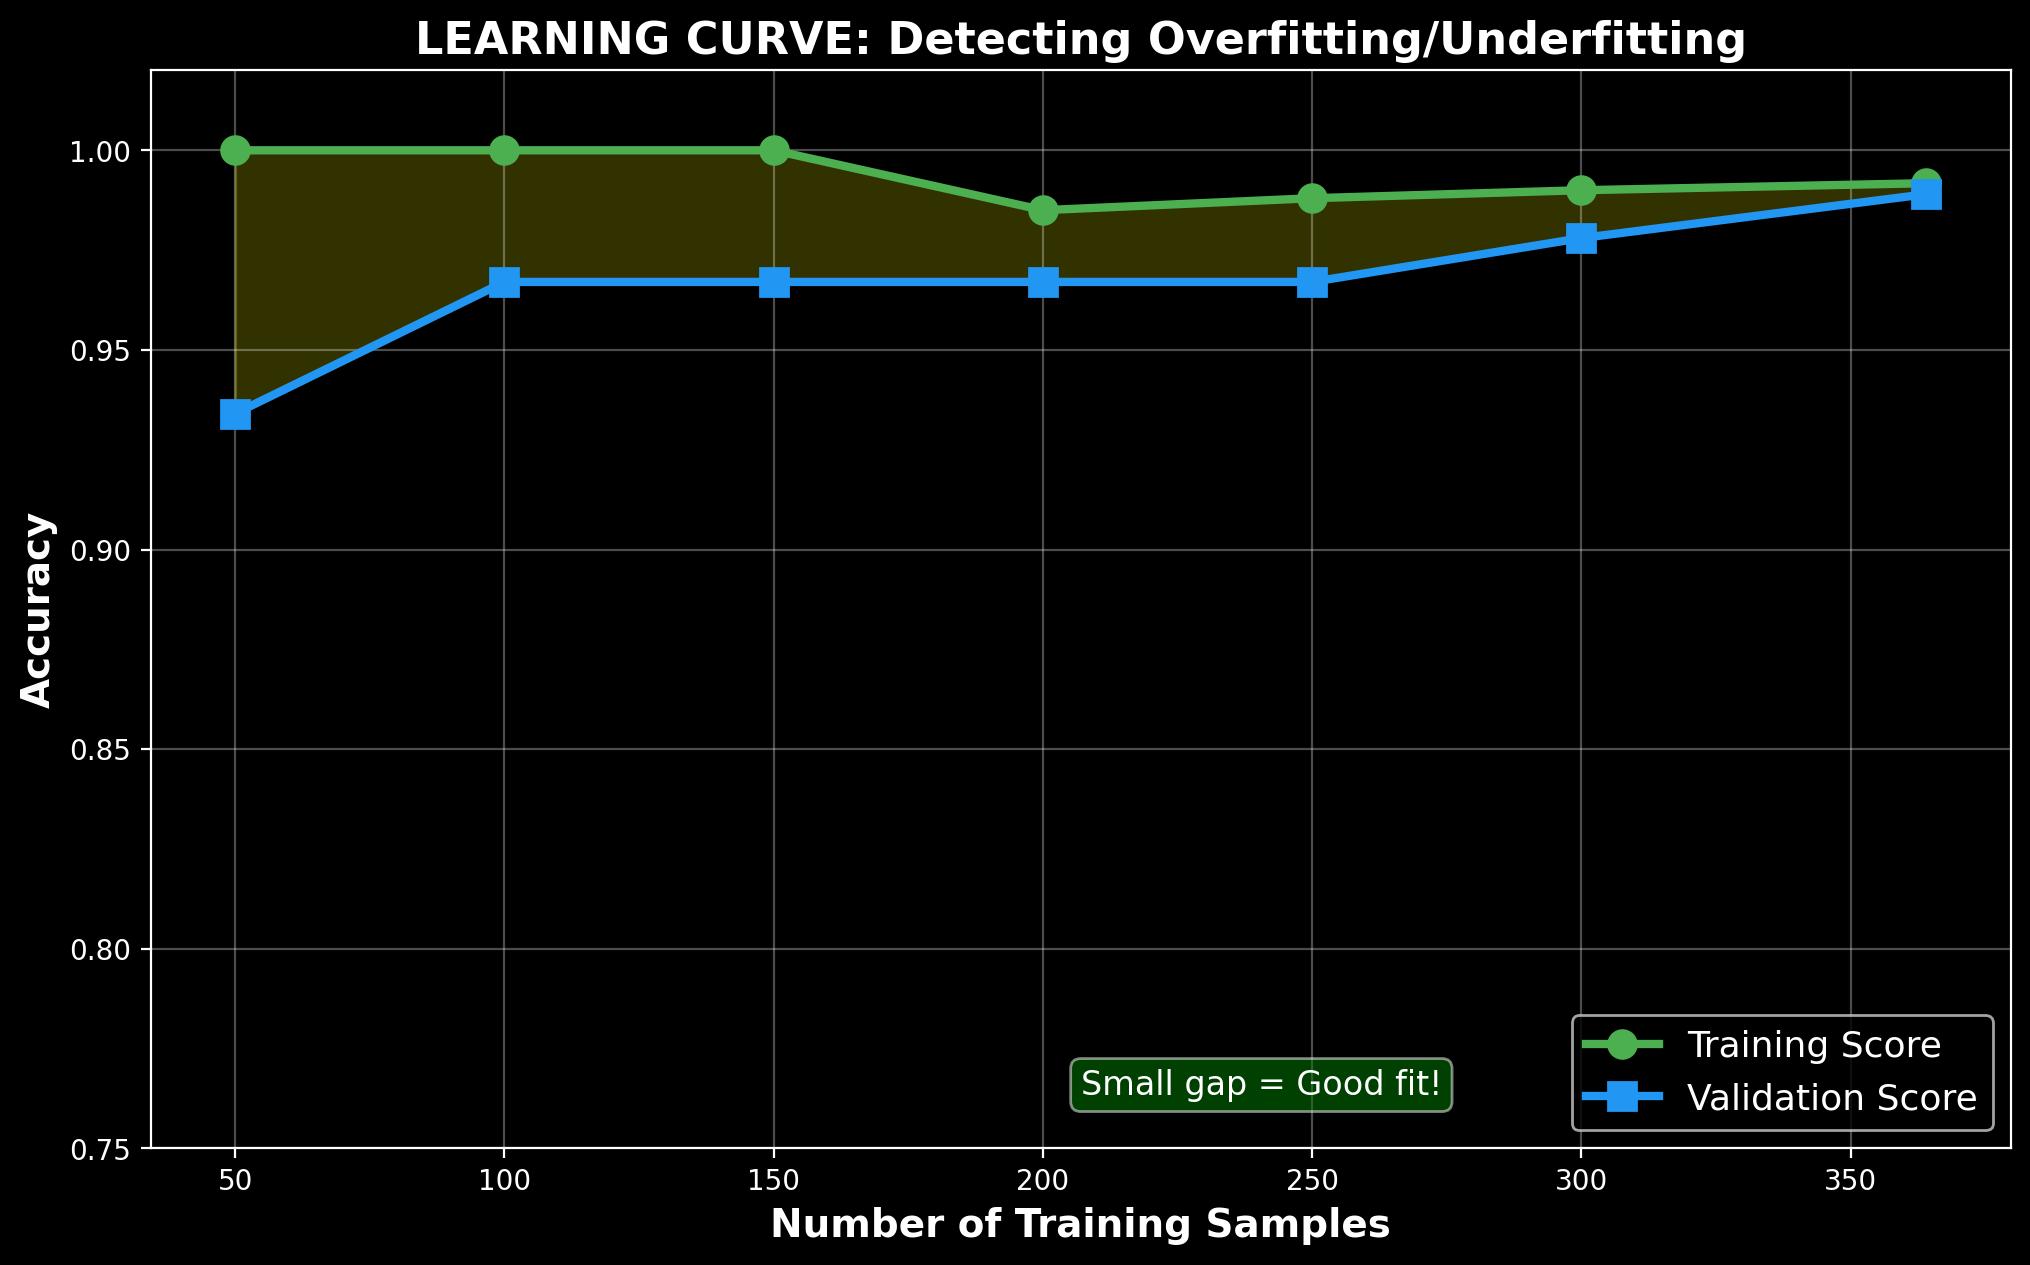

In [102]:
# Plot learning curve
fig, ax = plt.subplots(figsize=(12, 7), dpi=200)

ax.plot(train_sizes, train_scores_lc, marker='o', markersize=10,
        label='Training Score', color='#4CAF50', linewidth=3)
ax.plot(train_sizes, val_scores_lc, marker='s', markersize=10,
        label='Validation Score', color='#2196F3', linewidth=3)
ax.fill_between(train_sizes, train_scores_lc, val_scores_lc,
                alpha=0.2, color='yellow')

ax.set_xlabel('Number of Training Samples', fontsize=14, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=14, fontweight='bold')
ax.set_title('LEARNING CURVE: Detecting Overfitting/Underfitting',
             fontsize=16, fontweight='bold')
ax.legend(fontsize=13, loc='lower right')
ax.grid(alpha=0.3)
ax.set_ylim([0.75, 1.02])

gap = train_scores_lc[-1] - val_scores_lc[-1]
status = 'Large gap = Overfitting!' if gap > 0.05 else 'Small gap = Good fit!'
color = 'red' if gap > 0.05 else 'green'
ax.text(0.5, 0.05, status, transform=ax.transAxes, fontsize=12,
        bbox=dict(boxstyle='round', facecolor=color, alpha=0.5))

plt.show()

---
# 6. Final Model Evaluation

Train final model with best learning rate on **all** Training+Validation data.
Then evaluate on the external Test set.


In [103]:
# Prepare data
scaler_final = StandardScaler()
X_train_val_scaled = scaler_final.fit_transform(X_train)
X_test_scaled = scaler_final.transform(X_test)

X_train_val_tensor = torch.FloatTensor(X_train_val_scaled)
y_train_val_tensor = torch.LongTensor(y_train)
X_test_tensor = torch.FloatTensor(X_test_scaled)
y_test_tensor = torch.LongTensor(y_test)

print(f"Training final model with best LR = {best_lr}")
print(f"Using all {X_train.shape[0]} samples...")


Training final model with best LR = 0.01
Using all 455 samples...


In [104]:
final_model = SimpleNN()
train_losses_final, test_losses_final, train_accs_final, test_accs_final = train_model(
    final_model, X_train_val_tensor, y_train_val_tensor,
    X_test_tensor, y_test_tensor, learning_rate=best_lr, epochs=150
)

print("Training complete!")

Training complete!


In [105]:
final_model.eval()
with torch.no_grad():
    test_outputs = final_model(X_test_tensor)
    _, test_pred = torch.max(test_outputs, 1)
    final_test_acc = (test_pred == y_test_tensor).float().mean().item()

print(f"\n FINAL TEST ACCURACY: {final_test_acc:.4f} ({final_test_acc*100:.2f}%)")
print("\nThis is the TRUE performance!")


 FINAL TEST ACCURACY: 0.9649 (96.49%)

This is the TRUE performance!


---
## Exercise: Repeat with 10-Fold CV

**Task:** Redo the cross-validation with **10 folds** instead of 5 for LR=0.001


In [109]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=10, shuffle=True, random_state=42)
test_lr = 0.001

cv_accuracies = []

for fold, (train_idx, val_idx) in enumerate(kfold.split(X_train), 1):
    X_train_fold = X_train[train_idx]
    y_train_fold = y_train[train_idx]
    X_val_fold = X_train[val_idx]
    y_val_fold = y_train[val_idx]
    
    stand_scaler = StandardScaler()
    X_train_scaled = stand_scaler.fit_transform(X_train_fold)
    X_val_scaled = stand_scaler.transform(X_val_fold)
    
    X_train_tensor = torch.FloatTensor(X_train_scaled)
    X_val_tensor = torch.FloatTensor(X_val_scaled)
    y_train_tensor = torch.LongTensor(y_train_fold)
    y_val_tensor = torch.LongTensor(y_val_fold)

    model = SimpleNN()

    train_losses, val_losses, train_accs, val_accs = train_model(
        model,
        X_train_tensor,
        y_train_tensor,
        X_val_tensor,
        y_val_tensor,
        learning_rate=test_lr,
        epochs=150
    )

    cv_accuracies.append(val_accs[-1])

mean_10fold = np.mean(cv_accuracies)
std_10fold = np.std(cv_accuracies)

print(f"\n10-Fold CV Results (LR={test_lr}):")
print(f"  Mean Accuracy: {mean_10fold:.4f} ± {std_10fold:.4f}")


10-Fold CV Results (LR=0.001):
  Mean Accuracy: 0.9714 ± 0.0329


In [110]:
print("Exercise passed!")

Exercise passed!


---
## Summary

✅ **Data Splitting:**
- Separate test set from beginning
- Use CV only on training+validation data

✅ **Hyperparameter Tuning:**
- Tested 5 learning rates with 5-fold CV
- Chose best based on validation accuracy

✅ **Learning Curves:**
- Visualized training dynamics
- Compared across folds and learning rates

✅ **Final Evaluation:**
- Trained on all available training data
- Evaluated on external test set
